In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [12]:
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(123456)

beta=5.75911
b = 2.55
bk = 4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
# xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=3, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [13]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase1=3000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=50,
            bs=jnp.array([b])
        ) 

In [14]:
steady_record = my_driver.steady_record
transient_record = my_driver.transient_record
upper99_s = my_driver.upper99_s

eps = 1e-5
k99 = max(0, int(np.ceil(0.99 * my_driver.n_tested_patterns)) - 1)
k01 = max(0, int(np.ceil(0.01 * my_driver.n_tested_patterns)) - 1) 
upper99_transient = np.partition(transient_record[:, 0, :], k99, axis=-1)[:, k99] + eps
lower01_transient = np.partition(transient_record[:, 0, :], k01, axis=-1)[:, k01]
mean_transient = jnp.mean(transient_record[:, 0, :], axis=-1)

capa = utils.capacity_numba(my_driver.transient_record, my_driver.steady_record, upper99_s)

In [15]:
capa

array([864.5])

In [ ]:
# path = "../data/fixed_params/memory_response_vs_age/int_params3/coeff_3_"
# np.save(path + "upper99.npy", upper99_s)
# np.save(path + "transient_upper99.npy", upper99_transient)
# np.save(path + "transient_lower01.npy", lower01_transient)
# np.save(path + "transient_mean.npy", mean_transient)
# np.save(path + "capa.npy", capa)

In [7]:
path1 = "../data/fixed_params/memory_response_vs_age/nonInt_params3/coeff_infty_"
upper99_1 = np.load(path1 + "upper99.npy")
upper99_transient_1 = np.load(path1 + "transient_upper99.npy")
lower01_transient_1 = np.load(path1 + "transient_lower01.npy")
mean_transient_1 = np.load(path1 + "transient_mean.npy")
capa_1 = np.load(path1 + "capa.npy")

path2 = "../data/fixed_params/memory_response_vs_age/int_variableN_min1_params3/coeff_infty_"
upper99_2 = np.load(path2 + "upper99.npy")
upper99_transient_2 = np.load(path2 + "transient_upper99.npy")
lower01_transient_2 = np.load(path2 + "transient_lower01.npy")
mean_transient_2 = np.load(path2 + "transient_mean.npy")
capa_2 = np.load(path2 + "capa.npy")

path3 = "../data/fixed_params/memory_response_vs_age/int_params3/coeff_infty_"
upper99_3 = np.load(path3 + "upper99.npy")
upper99_transient_3 = np.load(path3 + "transient_upper99.npy")
lower01_transient_3 = np.load(path3 + "transient_lower01.npy")
mean_transient_3 = np.load(path3 + "transient_mean.npy")
capa_3 = np.load(path3 + "capa.npy")

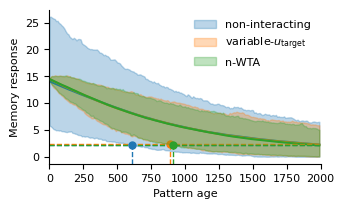

In [8]:
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

fig, ax = plt.subplots(figsize=(3.5, 2.0))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

xmax = 2000
plot_point_spacing = 10
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_1[::plot_point_spacing], lower01_transient_1[::plot_point_spacing], color='C0', alpha=0.3, label='non-interacting', zorder=1)
# ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_1[::plot_point_spacing])
    
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_2[::plot_point_spacing], lower01_transient_2[::plot_point_spacing], color='C1', alpha=0.3, label=r'variable-$u_{\text{target}}$', zorder=2)
# ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_2[::plot_point_spacing])
ax.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_3[::plot_point_spacing], lower01_transient_3[::plot_point_spacing], color='C2', alpha=0.3, label='n-WTA', zorder=3)

ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_1[::plot_point_spacing])
ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_2[::plot_point_spacing])
ax.plot(np.arange(0, xmax, plot_point_spacing), mean_transient_3[::plot_point_spacing])

y_min, y_max = ax.get_ylim()

ax.hlines(y=upper99_1[0], xmin=0, xmax=xmax, colors='C0', linestyles='--', linewidth=1.)
ax.vlines(x=capa_1[0], ymin=y_min, ymax=upper99_1[0], colors='C0', linestyles='--', linewidth=1.)
ax.hlines(y=upper99_2[0], xmin=0, xmax=xmax, colors='C1', linestyles='--', linewidth=1.)
ax.vlines(x=capa_2[0], ymin=y_min, ymax=upper99_2[0], colors='C1', linestyles='--', linewidth=1.)
ax.hlines(y=upper99_3[0], xmin=0, xmax=xmax, colors='C2', linestyles='--', linewidth=1.)
ax.vlines(x=capa_3[0], ymin=y_min, ymax=upper99_3[0], colors='C2', linestyles='--', linewidth=1.)
ax.plot(capa_1, upper99_1, color='C0', marker='o', markersize=5)
ax.plot(capa_2, upper99_2, color='C1', marker='o', markersize=5)
ax.plot(capa_3, upper99_3, color='C2', marker='o', markersize=5)

ax.set_xlim(0, xmax)
ax.set_ylim(y_min, y_max)

ax.set_xlabel("Pattern age");
ax.set_ylabel("Memory response");

ax.legend(fontsize=8, frameon=False)

# plt.savefig("../figures/fig2/memory_response_vs_age_coeff_infty_params3.pdf", bbox_inches="tight")

In [4]:
capa_1, capa_2, capa_3

(array([609.5]), array([888.]), array([909.5]))

In [5]:
capa_1, capa_2, capa_3

(array([252.]), array([762.33333333]), array([864.5]))

In [11]:
1-(864.5/909.5)

0.04947773501924135

In [3]:
# path1 = "../data/memory_response_vs_age/non_int/coeff_infty_"
# path1 = "../data/memory_response_vs_age/int_sameParams_as_nonInt/coeff_infty_"
path1 = "../data/memory_response_vs_age/int/coeff_infty_"
upper99_coeff_infty = np.load(path1 + "upper99.npy")
upper99_transient_coeff_infty = np.load(path1 + "transient_upper99.npy")
lower01_transient_coeff_infty = np.load(path1 + "transient_lower01.npy")
capa_coeff_infty = np.load(path1 + "capa.npy")

# path2 = "../data/memory_response_vs_age/non_int/coeff_4_"
# path2 = "../data/memory_response_vs_age/int_sameParams_as_nonInt/coeff_4_"
path2 = "../data/memory_response_vs_age/int/coeff_4_"
upper99_coeff4 = np.load(path2 + "upper99.npy")
upper99_transient_coeff4 = np.load(path2 + "transient_upper99.npy")
lower01_transient_coeff4 = np.load(path2 + "transient_lower01.npy")
capa_coeff4 = np.load(path2 + "capa.npy")

<function matplotlib.pyplot.savefig(*args, **kwargs) -> 'None'>

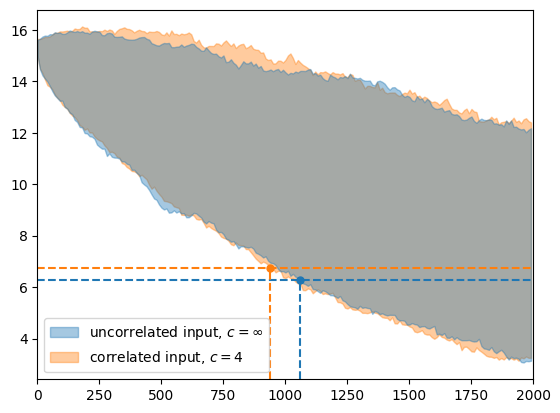

In [8]:
xmax = 2000
plot_point_spacing = 10
plt.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_coeff_infty[::plot_point_spacing], lower01_transient_coeff_infty[::plot_point_spacing], color='C0', alpha=0.4, label='uncorrelated input, $c=\infty$', zorder=2)

plt.fill_between(np.arange(0, xmax, plot_point_spacing), upper99_transient_coeff4[::plot_point_spacing], lower01_transient_coeff4[::plot_point_spacing], color='C1', alpha=0.4, label='correlated input, $c=4$', zorder=1)

y_min, y_max = plt.ylim()

plt.hlines(y=upper99_coeff_infty[0], xmin=0, xmax=xmax, colors='C0', linestyles='--', linewidth=1.5)
plt.vlines(x=capa_coeff_infty[0], ymin=y_min, ymax=upper99_coeff_infty[0], colors='C0', linestyles='--', linewidth=1.5)
plt.hlines(y=upper99_coeff4[0], xmin=0, xmax=xmax, colors='C1', linestyles='--', linewidth=1.5)
plt.vlines(x=capa_coeff4[0], ymin=y_min, ymax=upper99_coeff4[0], colors='C1', linestyles='--', linewidth=1.5)

plt.plot(capa_coeff_infty, upper99_coeff_infty, color='C0', marker='o', markersize=5)
plt.plot(capa_coeff4, upper99_coeff4, color='C1', marker='o', markersize=5)

plt.xlim(0, xmax)
plt.ylim(y_min, y_max)

plt.legend()

plt.savefig

In [10]:
import scipy
b = 2.55
bk =  4.0
n = 10
nd=300
n_samples = 500000
bla = np.sqrt(2)*scipy.special.erfcinv(2*n/nd)
xs = np.random.normal(0, 1, (nd, n_samples))
mask1 = xs > bla
indices1 = np.nonzero(mask1)
xs1 = xs[indices1]
xs2 = np.sort(xs, axis=0)
xs2 = xs2[-n:, :]
xs2 = xs2.flatten()

In [11]:
indices1 = np.nonzero(mask1)
xs1 = xs[indices1]

xs_sorted = np.sort(xs, axis=0)
xs_sorted = xs_sorted[-n:, :]

all_below_threshold = np.sum(mask1, axis=0) < 1 # (n_samples, )
indices2 = np.nonzero(all_below_threshold)
xs2_rank1 = xs_sorted[-1, indices2].flatten()
xs2 = np.concatenate([xs1, xs2_rank1], axis=0)

xs3 = xs_sorted.flatten()

In [12]:
indices2 = np.nonzero(all_below_threshold)
indices2

(array([ 15184,  29186,  38047,  39369,  55970, 170843, 202483, 212394,
        238753, 252116, 291222, 325403, 342594, 348941, 353889, 370521,
        388470, 403014, 418638, 456468]),)

Text(0, 0.5, 'Probability density')

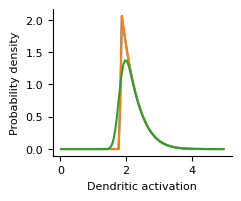

In [13]:
def hist_midpoints(data, bins, range_):
    counts, edges = np.histogram(data, bins=bins, range=range_, density=True)
    mids = 0.5 * (edges[:-1] + edges[1:])
    return mids, counts

fig, ax = plt.subplots(figsize=(2.3, 1.9), constrained_layout=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

xmin = 0.
xmax = 5.
bins = 100
range_ = (xmin, xmax)

for data, label in [
    (xs1, "non-interacting"),
    (xs2, r'variable-$u_{\text{target}}$'),
    (xs3, "n-WTA"),
]:
    mids, counts = hist_midpoints(data, bins, range_)
    ax.plot(mids, counts, label=label)

# plt.hist(xs1, bins=500, density=True, histtype='step', label='non-interacting', color='C0')
# plt.hist(xs2, bins=500, density=True, histtype='step', label=r'variable-$u_{\text{target}}$', color='C1')
# plt.hist(xs3, bins=500, density=True, histtype='step', label='n-WTA', color='C2')
ax.set_xlabel('Dendritic activation')
ax.set_ylabel('Probability density')
# ax.legend()

In [14]:
np.mean(xs1), np.var(xs1), np.mean(xs2), np.var(xs2), np.mean(xs3), np.var(xs3)

(np.float64(2.227055547614433),
 np.float64(0.12479814544787816),
 np.float64(2.2270538255922308),
 np.float64(0.1247983903533732),
 np.float64(2.20568267106681),
 np.float64(0.14117272484989696))

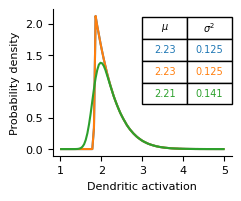

In [16]:
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Calculate mean and variance for each dataset
stats_data = [
    ('non-interacting', np.mean(xs1), np.var(xs1)),
    (r'variable-$u_{\text{target}}$', np.mean(xs2), np.var(xs2)),
    ('n-WTA', np.mean(xs3), np.var(xs3))
]

# Create figure with histogram and table
fig, ax = plt.subplots(figsize=(2.3, 1.9), constrained_layout=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

xmin = 1.
xmax = 5.
bins = 100
range_ = (xmin, xmax)

for data, label in [
    (xs1, "non-interacting"),
    (xs2, r'variable-$u_{\text{target}}$'),
    (xs3, "n-WTA"),
]:
    mids, counts = hist_midpoints(data, bins, range_)
    ax.plot(mids, counts, label=label)

ax.set_xlabel('Dendritic activation')
ax.set_ylabel('Probability density')

# Create table data
table_data = [[f'{mu:.2f}', f'{var:.3f}'] for _, mu, var in stats_data]
# row_labels = [label for label, _, _ in stats_data]

# Add table
table = ax.table(cellText=table_data,
                # rowLabels=row_labels,
                colLabels=[r'$\mu$', r'$\sigma^2$'],
                cellLoc='center',
                rowLoc='right',
                loc='upper right',
                bbox=[0.5, 0.35, 0.5, 0.6])

table.auto_set_font_size(False)
table.set_fontsize(7)

row_colors = ['C0', 'C1', 'C2']
for i, color in enumerate(row_colors, start=1):
    for j in range(2):
        table[(i, j)].get_text().set_color(color)

plt.savefig("../figures/fig2/u_distribution_before_learning.pdf", bbox_inches="tight")

In [ ]:
# Recreate the table with custom position/size and colored text
table.remove()

table = ax.table(
    cellText=table_data,
    colLabels=[r'$\mu$', r'$\sigma^2$'],
    cellLoc='center',
    loc='upper right',
    bbox=[0.63, 0.62, 0.34, 0.30]  # [left, bottom, width, height] in axes coords
)

table.auto_set_font_size(False)
table.set_fontsize(5)

row_colors = ['C0', 'C1', 'C2']
for i, color in enumerate(row_colors, start=1):
    for j in range(2):
        table[(i, j)].get_text().set_color(color)

fig.canvas.draw_idle()